In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

# Define the column names for the Auto MPG dataset
column_names = ['mpg', 'cylinders', 'displacement', 'horsepower', 'weight',
                'acceleration', 'model_year', 'origin', 'car_name']

# Load the dataset using whitespace delimiter
df = pd.read_csv('/content/auto-mpg.data', names=column_names, sep='\s+', na_values='?')
print(df.head())

# Drop rows with missing values
df.dropna(inplace=True)

X = df[['displacement']]
y = df[['mpg']]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
y_pred_poly = poly_model.predict(X_test_poly)

print('Linear Model MSE:', mean_squared_error(y_test, y_pred_linear))
print('Linear Model R2 Score:', r2_score(y_test, y_pred_linear))
print('Polynomial Model MSE:', mean_squared_error(y_test, y_pred_poly))
print('Polynomial Model R2 Score:', r2_score(y_test, y_pred_poly))

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0  3504.0          12.0   
1  15.0          8         350.0       165.0  3693.0          11.5   
2  18.0          8         318.0       150.0  3436.0          11.0   
3  16.0          8         304.0       150.0  3433.0          12.0   
4  17.0          8         302.0       140.0  3449.0          10.5   

   model_year  origin                   car_name  
0          70       1  chevrolet chevelle malibu  
1          70       1          buick skylark 320  
2          70       1         plymouth satellite  
3          70       1              amc rebel sst  
4          70       1                ford torino  
Linear Model MSE: 21.227484289611397
Linear Model R2 Score: 0.5841057656051312
Polynomial Model MSE: 20.649054718307305
Polynomial Model R2 Score: 0.5954385038809804


<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:14: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_14219/3717534919.py:14: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('/content/auto-mpg.data', names=column_names, sep='\s+', na_values='?')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


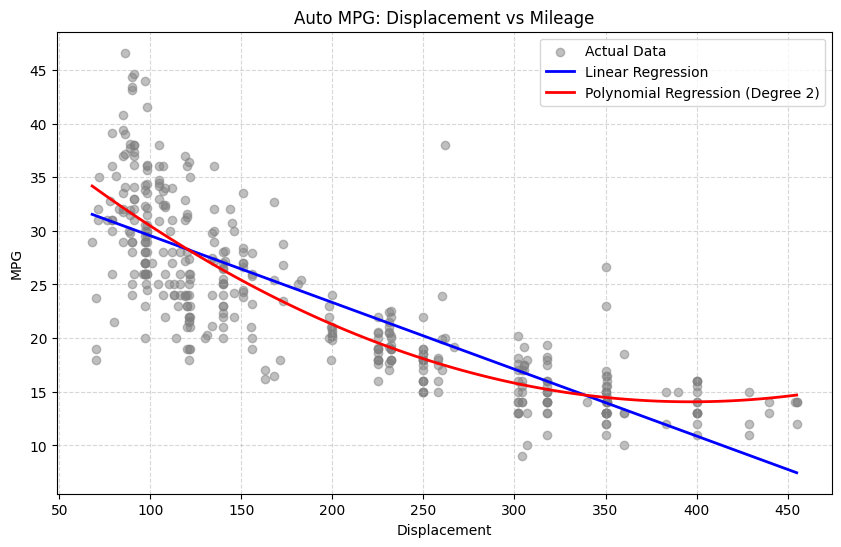

In [5]:
import matplotlib.pyplot as plt
import numpy as np

# Create a range of values for plotting the smooth curves
X_range = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)

# Predictions over the range
y_range_linear = linear_model.predict(X_range)
X_range_poly = poly.transform(X_range)
y_range_poly = poly_model.predict(X_range_poly)

# Plot actual data points and regression models
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='gray', alpha=0.5, label='Actual Data')
plt.plot(X_range, y_range_linear, color='blue', linewidth=2, label='Linear Regression')
plt.plot(X_range, y_range_poly, color='red', linewidth=2, label='Polynomial Regression (Degree 2)')

plt.title('Auto MPG: Displacement vs Mileage')
plt.xlabel('Displacement')
plt.ylabel('MPG')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Explanation of Each Step in the Workflow

#### 1. Importing Libraries
We import essential libraries for our analysis:
* `pandas` and `numpy` for data manipulation and mathematical operations.
* `matplotlib.pyplot` for data visualization.
* `sklearn` (scikit-learn) modules for splitting data, building Linear/Polynomial models, and computing performance metrics.

#### 2. Loading the Dataset
* **Parsing raw data:** The Auto MPG dataset is loaded using `pd.read_csv` with a whitespace delimiter (`sep='\s+'`) because the data values are separated by spaces rather than commas.
* **Column names:** We explicitly define standard headers (`column_names`) since the raw data file does not contain a header row.
* **Missing values:** We set `na_values='?'` to automatically recognize question marks as missing values (`NaN`).

#### 3. Data Cleaning
* **Removing Nulls:** We drop any incomplete rows containing missing values (`NaN`) using `df.dropna(inplace=True)` to ensure our regression algorithms run correctly.

#### 4. Defining Features (X) and Target (y)
* **Independent Variable (X):** We select `displacement` (engine size) as the feature we will use to predict fuel efficiency.
* **Dependent Variable (y):** We select `mpg` (miles per gallon) as the target variable we want to predict.

#### 5. Train-Test Split
* Using `train_test_split`, we partition the data into a training set (80%) and a testing set (20%). This allows us to train our models on one subset and objectively evaluate their performance on unseen data.

#### 6. Linear Regression Model
* **Training:** We initialize and fit a `LinearRegression` model using the training features (`X_train`) and labels (`y_train`).
* **Prediction:** We predict fuel efficiency on the test set (`X_test`).

#### 7. Polynomial Regression Model (Degree 2)
* **Feature Transformation:** Since the relationship between engine displacement and mileage is curved (non-linear), we use `PolynomialFeatures(degree=2)` to generate quadratic terms ($X^2$) alongside the linear terms.
* **Training and Prediction:** We fit another linear regression model on these transformed features to construct our non-linear curve.

#### 8. Performance Evaluation
We evaluate both models using two standard metrics:
* **Mean Squared Error (MSE):** Measures the average squared difference between actual and predicted values (lower is better).
* **R-squared ($R^2$) Score:** Indicates the percentage of variance in MPG explained by the model (higher is better, closer to 1.0).

#### 9. Visual Comparison
* Finally, we create a scatter plot of the original data points alongside the regression lines. The plot shows that the curved **Polynomial Regression** line fits the downward-sloping, curved distribution of the data much more naturally than the straight **Linear Regression** line.